# 09 · Results summary (all eight test configurations)

All numbers come from the compiled results file `reports/results.json` (`scripts/compile_report.py`), which reads each run's evaluation output. The headline exact F1 values are re-checked below against the saved predictions.

In [1]:
%matplotlib inline
import json, statistics
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd
from nbcommon import *

pd.set_option("display.max_colwidth", 80)
RUN_GPU = False   # True only on the training/inference machine (needs the models and a GPU)
print("project:", ROOT.name, "| run outputs read from:", A.relative_to(ROOT))

project: FinalProject | run outputs read from: artifacts


In [2]:
R = load_json(ROOT / "reports/results.json")
order = ["E1", "E2", "M1", "M2"]
rows = []
for alias in order:
    t = R["test"][alias]
    rows += [(f"{alias} zero-shot", t["ZS"]), (f"{alias} LoRA", t["FT"])]
display(metric_table(rows))

,videos,failed,exact_f1,tolerant_f1,pk,window_diff,boundary_similarity,title_rouge_l,title_bertscore,pred_per_ref_chapters
configuration,,,,,,,,,,
E1 zero-shot,1448,1435,0.003,0.004,0.995,0.997,0.002,0.002,0.002,0.017
E1 LoRA,1448,27,0.484,0.663,0.244,0.265,0.461,0.365,0.634,0.945
E2 zero-shot,1448,477,0.149,0.233,0.584,0.611,0.137,0.172,0.201,0.640
E2 LoRA,1448,4,0.500,0.679,0.229,0.251,0.476,0.377,0.651,0.961
M1 zero-shot,1448,4,0.403,0.625,0.293,0.339,0.386,0.254,0.626,1.246
M1 LoRA,1448,116,0.365,0.571,0.339,0.369,0.355,0.268,0.561,0.969
M2 zero-shot,1448,1,0.451,0.643,0.286,0.347,0.420,0.303,0.677,1.477
M2 LoRA,1448,46,0.344,0.540,0.306,0.326,0.334,0.282,0.507,0.812


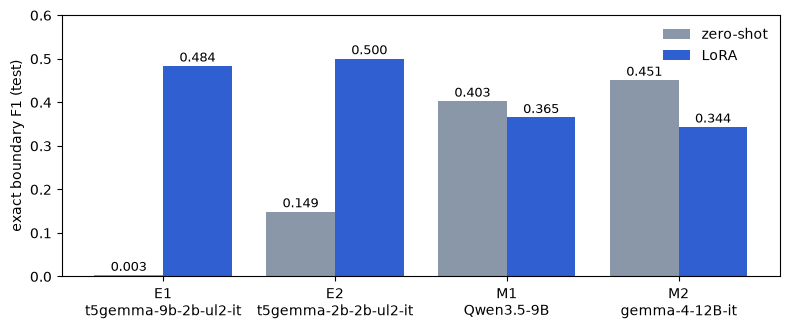

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = range(len(order))
zs = [R["test"][a]["ZS"]["exact_f1"] for a in order]
ft = [R["test"][a]["FT"]["exact_f1"] for a in order]
ax.bar([i - .2 for i in x], zs, .4, color="#8a97a8", label="zero-shot")
ax.bar([i + .2 for i in x], ft, .4, color="#2f5fd0", label="LoRA")
for i, (a, b) in enumerate(zip(zs, ft)):
    ax.text(i - .2, a + .01, f"{a:.3f}", ha="center", fontsize=9); ax.text(i + .2, b + .01, f"{b:.3f}", ha="center", fontsize=9)
ax.set_xticks(list(x), [f"{a}\n{BACKBONES[a]['model_id'].split('/')[1]}" for a in order])
ax.set_ylabel("exact boundary F1 (test)"); ax.set_ylim(0, .6); ax.legend(frameon=False); plt.tight_layout()

## LoRA effect (paired bootstrap) and dev → test consistency

In [4]:
rows = []
for alias in order:
    t, d = R["test"][alias]["ft_minus_zs_exact_f1"], R["dev"][alias]["ft_minus_zs_exact_f1"]
    rows.append({"backbone": alias, "dev LoRA − ZS": "%+.3f [%+.3f, %+.3f]" % (d["mean_difference"], *d["confidence_interval"]),
                 "test LoRA − ZS": "%+.3f [%+.3f, %+.3f]" % (t["mean_difference"], *t["confidence_interval"]),
                 "failed ZS / LoRA (test)": f'{R["test"][alias]["ZS"]["failed"]} / {R["test"][alias]["FT"]["failed"]}'})
display(pd.DataFrame(rows).set_index("backbone"))
print("Post-hoc cross-backbone comparisons on test:")
for p in R["posthoc_test_comparisons"]:
    print(f"  {p['left']} − {p['right']}: {p['mean_difference']:+.3f} [{p['ci95'][0]:+.3f}, {p['ci95'][1]:+.3f}]")

,dev LoRA − ZS,test LoRA − ZS,failed ZS / LoRA (test)
backbone,,,
E1,"+0.508 [+0.466, +0.550]","+0.481 [+0.465, +0.497]",1435 / 27
E2,"+0.321 [+0.276, +0.367]","+0.352 [+0.335, +0.368]",477 / 4
M1,"-0.042 [-0.072, -0.012]","-0.038 [-0.049, -0.026]",4 / 116
M2,"-0.114 [-0.144, -0.084]","-0.108 [-0.119, -0.096]",1 / 46


Post-hoc cross-backbone comparisons on test:
  E2-FT − E1-FT: +0.017 [+0.008, +0.026]
  E2-FT − M2-ZS: +0.049 [+0.039, +0.059]
  E1-FT − M2-ZS: +0.033 [+0.022, +0.043]
  M2-ZS − M1-ZS: +0.048 [+0.039, +0.057]


## Re-check headline numbers from the saved predictions

In [5]:
if TEST_RECORDS.exists():
    for alias in order:
        for arm in ["ZS", "FT"]:
            value = recompute(TEST_RECORDS, BACKBONES[alias]["runs"][("test", arm)] / "predictions.jsonl")["aggregate"]["macro_exact_f1"]
            assert abs(value - R["test"][alias][arm]["exact_f1"]) < 1e-12, (alias, arm)
    print("all eight test exact-F1 values reproduce from saved predictions")
else:
    print("skipped: rebuild the test records first (scripts/prepare_test.py); transcripts are not redistributed")

all eight test exact-F1 values reproduce from saved predictions


## Rejection-sampling fine-tuning (dev only)

In [6]:
rows = []
for alias in ["M1", "M2"]:
    rows += [(f"{alias} zero-shot", R["dev"][alias]["ZS"]), (f"{alias} direct LoRA", R["dev"][alias]["FT"]),
             (f"{alias} RFT v1", R["rft"][alias]["RFT"]), (f"{alias} RFT v2", R["rft_v2"][alias]["RFT"])]
display(metric_table(rows))

,videos,failed,exact_f1,tolerant_f1,pk,window_diff,boundary_similarity,title_rouge_l,title_bertscore,pred_per_ref_chapters
configuration,,,,,,,,,,
M1 zero-shot,200,1,0.420,0.645,0.277,0.316,0.403,0.256,0.644,1.166
M1 direct LoRA,200,10,0.379,0.598,0.312,0.341,0.367,0.272,0.588,0.986
M1 RFT v1,200,0,0.409,0.634,0.283,0.323,0.387,0.233,0.621,1.170
M1 RFT v2,200,4,0.440,0.648,0.276,0.312,0.419,0.236,0.626,1.092
M2 zero-shot,200,0,0.459,0.649,0.283,0.342,0.430,0.305,0.692,1.464
M2 direct LoRA,200,8,0.346,0.543,0.310,0.333,0.339,0.272,0.484,0.786
M2 RFT v1,200,0,0.467,0.651,0.285,0.343,0.431,0.294,0.686,1.480
M2 RFT v2,200,0,0.464,0.650,0.285,0.344,0.427,0.300,0.687,1.465


## Compute and time

In [7]:
train = pd.DataFrame([{"recipe": r["recipe"], "model": r["alias"], "windows": r.get("actual_steps"),
                       "minutes": round(r["training_seconds"] / 60, 1) if r.get("training_seconds") else None,
                       "peak GiB": round(r["peak_allocated_bytes"] / 2**30) if r.get("peak_allocated_bytes") else None}
                      for r in R["training_runs"]]).set_index(["recipe", "model"])
display(train)
timing = pd.DataFrame(R["timing"])
test_timing = timing[timing.stage.str.startswith("Test")].assign(minutes=lambda f: (f.generation_seconds / 60).round(1))
display(test_timing[["model", "arm", "device", "engine", "minutes", "seconds_per_video", "output_tokens", "failed_videos"]].set_index(["model", "arm"]))

windows  minutes  peak GiB
recipe      model                            
Direct LoRA E1        1306     47.0        45
            E2        1306     29.0        21
            M1        1306     17.4        44
            M2        1306     40.9        56
RFT v1 LoRA M1         146      2.6        80
            M2         134      7.4        97
RFT v2 LoRA M1         599     12.0        87
            M2         573     34.8       105

device                    engine  minutes  seconds_per_video  \
model arm                                                                
E1    ZS    GPU2         HF batched greedy    339.2          14.054832   
      FT    GPU0         HF batched greedy     62.3           2.581723   
E2    ZS    GPU0         HF batched greedy    101.1           4.190968   
      FT    GPU0         HF batched greedy     29.8           1.235655   
M1    ZS    GPU0  vLLM, max 100 concurrent     37.9           1.569453   
      FT    GPU0  vLLM, max 100 concurrent     50.4           2.087915   
M2    ZS    GPU0  vLLM, max 100 concurrent     56.7           2.350673   
      FT    GPU0  vLLM, max 100 concurrent      6.3           0.261355   

           output_tokens  failed_videos  
model arm                                
E1    ZS         1578478           1435  
      FT          198479             27  
E2    ZS          763039            477  
      FT          192015              4  
M1    ZS        14885122              4  
      FT         7864948            116  
M2    ZS        10287209              1  
      FT          170337             46

## Conclusions

* **Best system: E2 (T5Gemma 2B-2B) + LoRA**, exact F1 0.500 on test. The smaller encoder-decoder beats the 9B-2B one and every decoder-only setup.
* **LoRA effect depends on architecture.** It is essential for the encoder-decoders, whose zero-shot output mostly fails the format. Answer-only LoRA *hurts* the reasoning decoder-only models (M1 −0.038, M2 −0.108) because it suppresses their native thinking.
* **RFT on the model's own reasoning** repairs that; with 1,306 windows, M1 reaches 0.440 on dev, above zero-shot (dev only).
* **Limitations:** pilot-scale adapters (1,000 videos, one pass, one seed); M1's adapter covers only 8 of 32 layers; multi-window videos remain much harder.